# Beginner findings 8-11: close approaches and fireballs

Sections B and C were not explored step by step in their own notebooks (the background builders stopped on a
usage limit), so the numbers each finding needs are computed here straight from the data files and saved to
`numbers/BF08...csv` to `numbers/BF11...csv`, with a chart for each finding in `charts/`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from global_land_mask import globe

import helpers as hp
import simple_charts as kc
from bf_tools import Facts, Meet, n0, d, p, g

hp.chart_style()
ca = hp.read_csv("close_approaches", usecols=["des", "cd", "dist", "v_rel", "h", "fullname"])
ca["t"] = pd.to_datetime(ca["cd"], format="%Y-%b-%d %H:%M")
ca["year"] = ca["t"].dt.year
print(f"{len(ca):,} passes, years {ca['year'].min()}-{ca['year'].max()}")

120,071 passes, years 1900-2199


## Finding 8: close passes bunch up around today because that's when we find them

                 key          value              shown             unit                                source
0               rows  120071.000000            120,071                                               our data
1            objects   28430.000000             28,430                                               our data
2           range_au       0.100000                0.1               AU                          rule we used
3           range_ld      38.910506                 39  lunar distances                              our data
4              ld_au       0.002570            0.00257               AU         the brief  (1 lunar distance)
5              ld_km  384400.000000            384,400               km         the brief  (1 lunar distance)
6      dec_1900s_avg    3322.600000              3,323                                               our data
7        dec_1900s_n      10.000000                 10                                               our data
8         

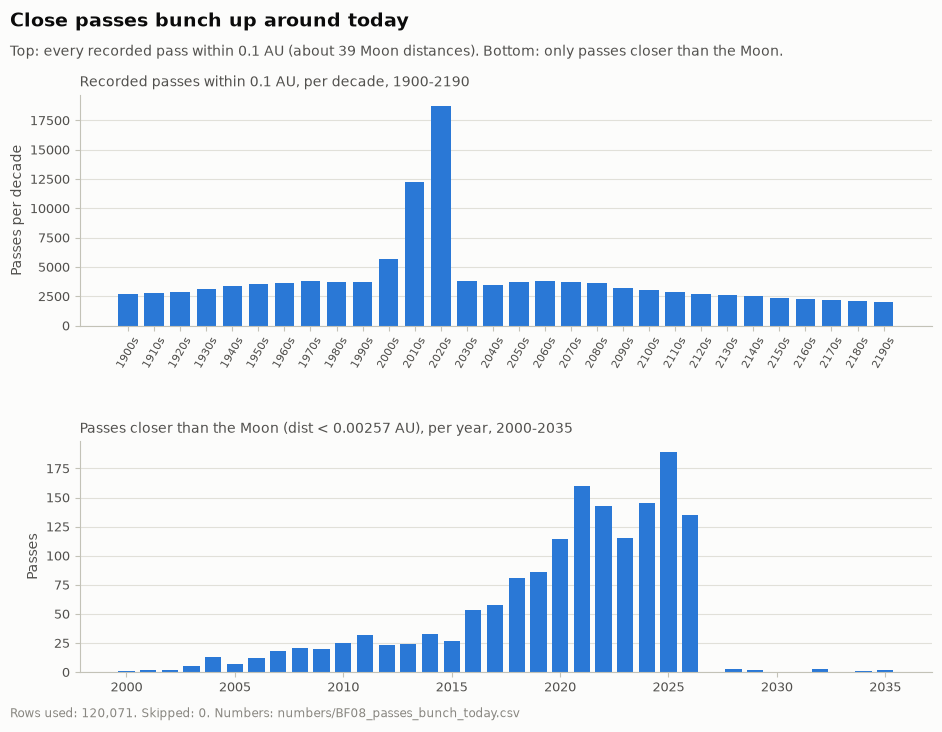

In [2]:
F = Facts(8, "passes_bunch_today")
F.add("rows", len(ca)); F.add("objects", ca["des"].nunique())
F.rule("range_au", 0.1, "0.1", "AU"); F.add("range_ld", 0.1 / hp.LD_AU, n0(0.1 / hp.LD_AU), "lunar distances")
F.outside("ld_au", hp.LD_AU, "0.00257", "AU", source="the brief (1 lunar distance)")
F.outside("ld_km", hp.LD_KM, "384,400", "km", source="the brief (1 lunar distance)")
dec = (ca["year"] // 10) * 10
per_dec = dec.value_counts().sort_index()
old = per_dec.loc[1900:1990]
F.add("dec_1900s_avg", old.mean(), n0(old.mean())); F.add("dec_1900s_n", len(old))
for y_ in (2010, 2020, 2030):
    F.add(f"dec_{y_}", int(per_dec[y_]))
F.add("drop_2020s_2030s", per_dec[2020] / per_dec[2030], d(per_dec[2020] / per_dec[2030], 1))
moon = ca[ca["dist"] < hp.LD_AU]
mpy = moon["year"].value_counts()
for y_ in (2025, 2026, 2027, 2028):
    F.add(f"moon_{y_}", int(mpy.get(y_, 0)))
F.add("last_date", 0, ca.loc[ca["year"] == 2026, "t"].max().strftime("%Y-%m-%d"), source="our data (date)")
ex = ca.loc[ca.loc[ca["year"] == 2025, "dist"].idxmin()]
F.add("ex_name", 0, ex["fullname"].strip().strip("()"), source="our data (name)")
F.add("ex_dist_au", ex["dist"], g(ex["dist"], 2), "AU")
F.add("ex_km", ex["dist"] * hp.AU_KM, n0(ex["dist"] * hp.AU_KM), "km")
F.add("ex_height", ex["dist"] * hp.AU_KM - hp.EARTH_RADIUS_KM, n0(ex["dist"] * hp.AU_KM - hp.EARTH_RADIUS_KM), "km")
F.outside("earth_radius", hp.EARTH_RADIUS_KM, "6,371", "km", source="the brief")
F.outside("au_km", hp.AU_KM / 1e6, "149.6", "million km")
F.outside("iss_km", 400, "400", "km", source="known science (space station height)")
F.add("ex_cd", 0, ex["cd"], source="our data (date)"); F.add("ex_des", 0, ex["des"], source="our data (name)")
F.rule("dec_1900s_label", 0, "1900s to 1990s"); F.rule("lbl_2010", 0, "2010s"); F.rule("lbl_2020", 0, "2020s"); F.rule("lbl_2030", 0, "2030s")
F.rule("yr_2027", 2027, "2027"); F.rule("yr_2028", 2028, "2028"); F.rule("yr_2025", 2025, "2025"); F.rule("yr_2026", 2026, "2026")
print(F.table().to_string()); f8 = F.save()

fig, axs = plt.subplots(2, 1, figsize=(11, 7.5), gridspec_kw={"hspace": 0.5})
decs = list(range(1900, 2200, 10))
v = per_dec.reindex(decs, fill_value=0)
axs[0].bar([f"{x}s" for x in decs], v.values, color=hp.SERIES[0], width=0.75)
axs[0].tick_params(axis="x", labelrotation=60, labelsize=8)
axs[0].set_ylabel("Passes per decade")
axs[0].set_title("Recorded passes within 0.1 AU, per decade, 1900-2190", fontsize=10, color=hp.INK_2)
yrs = list(range(2000, 2036))
mv = mpy.reindex(yrs, fill_value=0)
axs[1].bar(yrs, mv.values, color=hp.SERIES[0], width=0.75)
axs[1].set_ylabel("Passes")
axs[1].set_title("Passes closer than the Moon (dist < 0.00257 AU), per year, 2000-2035", fontsize=10, color=hp.INK_2)
for ax in axs:
    ax.grid(axis="x", visible=False)
hp.add_titles(fig, "Close passes bunch up around today",
              "Top: every recorded pass within 0.1 AU (about 39 Moon distances). Bottom: only passes closer than the Moon.",
              hp.caption(len(ca), 0, numbers_file="numbers/BF08_passes_bunch_today.csv"))
c8 = hp.save_chart(fig, "BF08_passes_per_decade"); plt.show()
hp.log_entry("B-BF08", "Beginner finding 8 chart: passes per decade and passes closer than the Moon per year", step=6,
             chart=c8, numbers=f8, rows_used=len(ca), rows_skipped=0,
             key_numbers=[f"2010s {per_dec[2010]:,}; 2020s {per_dec[2020]:,}; 2030s {per_dec[2030]:,}",
                          "closer than the Moon: " + ", ".join(f"{y_} {int(mpy.get(y_, 0))}" for y_ in (2025, 2026, 2027, 2028))],
             what_it_shows="Recorded passes pile up in the 2010s and 2020s and drop sharply after.")

## Finding 9: July is quiet, for the telescopes

                key         value              shown unit            source
0            y_from   2005.000000               2005           rule we used
1              y_to   2025.000000               2025           rule we used
2             h_cut     25.000000                 25           rule we used
3              rows  30810.000000             30,810               our data
4        small_rows  18547.000000             18,547               our data
5         small_jul    691.000000                691               our data
6         small_oct   2555.000000              2,555               our data
7             ratio      3.697540                3.7               our data
8   small_min_month      0.000000               July       our data (month)
9   small_max_month      0.000000            October       our data (month)
10          all_jul   1519.000000              1,519               our data
11          all_oct   3866.000000              3,866               our data
12         s

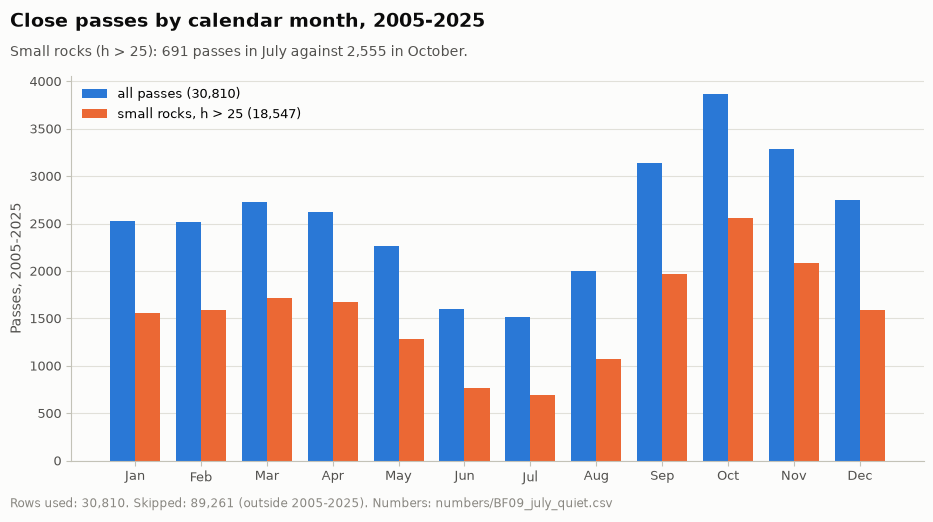

In [3]:
F = Facts(9, "july_quiet")
F.rule("y_from", 2005, "2005"); F.rule("y_to", 2025, "2025"); F.rule("h_cut", 25, "25")
w = ca[(ca["year"] >= 2005) & (ca["year"] <= 2025)].copy()
w["month"] = w["t"].dt.month
small = w[w["h"] > 25]
ms, ma_ = small["month"].value_counts().reindex(range(1, 13), fill_value=0), w["month"].value_counts().reindex(range(1, 13), fill_value=0)
F.add("rows", len(w)); F.add("small_rows", len(small))
F.add("small_jul", int(ms[7])); F.add("small_oct", int(ms[10])); F.add("ratio", ms[10] / ms[7], d(ms[10] / ms[7], 1))
F.add("small_min_month", 0, pd.Timestamp(2000, int(ms.idxmin()), 1).strftime("%B"), source="our data (month)")
F.add("small_max_month", 0, pd.Timestamp(2000, int(ms.idxmax()), 1).strftime("%B"), source="our data (month)")
F.add("all_jul", int(ma_[7])); F.add("all_oct", int(ma_[10]))
F.add("size_h25", hp.size_from_H(25, 0.14) * 1000, n0(hp.size_from_H(25, 0.14) * 1000), "m")
F.rule("albedo_guess", 0.14, "0.14")
F.add("h_blank", int(w["h"].isna().sum()))
exs = small.sort_values("t").iloc[0]
F.add("ex_cd", 0, exs["cd"], source="our data (date)"); F.add("ex_h", exs["h"], d(exs["h"], 2)); F.add("ex_dist", exs["dist"], g(exs["dist"], 3), "AU")
F.outside("guide_size", 30, "30", "m", source="Field Guide")
F.add("ex_name", 0, exs["fullname"].strip().strip("()"), source="our data (name)")
print(F.table().to_string()); f9 = F.save()
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(12); wd = 0.38
ax.bar(x - wd / 2, ma_.values, width=wd, color=hp.SERIES[0], label=f"all passes ({len(w):,})")
ax.bar(x + wd / 2, ms.values, width=wd, color=hp.SERIES[1], label=f"small rocks, h > 25 ({len(small):,})")
ax.set_xticks(x, ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_ylabel("Passes, 2005-2025")
ax.legend(loc="upper left"); ax.grid(axis="x", visible=False)
hp.add_titles(fig, "Close passes by calendar month, 2005-2025",
              f"Small rocks (h > 25): {ms[7]:,} passes in July against {ms[10]:,} in October.",
              hp.caption(len(w), len(ca) - len(w), "outside 2005-2025", "numbers/BF09_july_quiet.csv"))
c9 = hp.save_chart(fig, "BF09_passes_by_month"); plt.show()
hp.log_entry("B-BF09", "Beginner finding 9 chart: passes by calendar month, 2005-2025", step=6, chart=c9, numbers=f9,
             rows_used=len(w), rows_skipped=f"{len(ca) - len(w):,} (outside 2005-2025)",
             key_numbers=[f"h > 25: July {ms[7]:,}, October {ms[10]:,}"],
             what_it_shows=f"Small-rock passes in October outnumber July {ms[10] / ms[7]:.1f} to 1.")

## Finding 10: fireballs hit anywhere, and one dwarfs all the rest

                   key        value       shown           unit                                                     source
0                 rows  1074.000000       1,074                                                                  our data
1              located   888.000000         888                                                                  our data
2                first     0.000000  1988-04-15                                                           our data (date)
3                 last     0.000000  2026-10-04                                                           our data (date)
4     band_-90_-60_obs    58.000000          58                                                                  our data
5     band_-90_-60_exp    59.484721          59                                                                  our data
6   band_-90_-60_share     6.698730        6.7%                                                                  our data
7     band_-60_-30_obs  

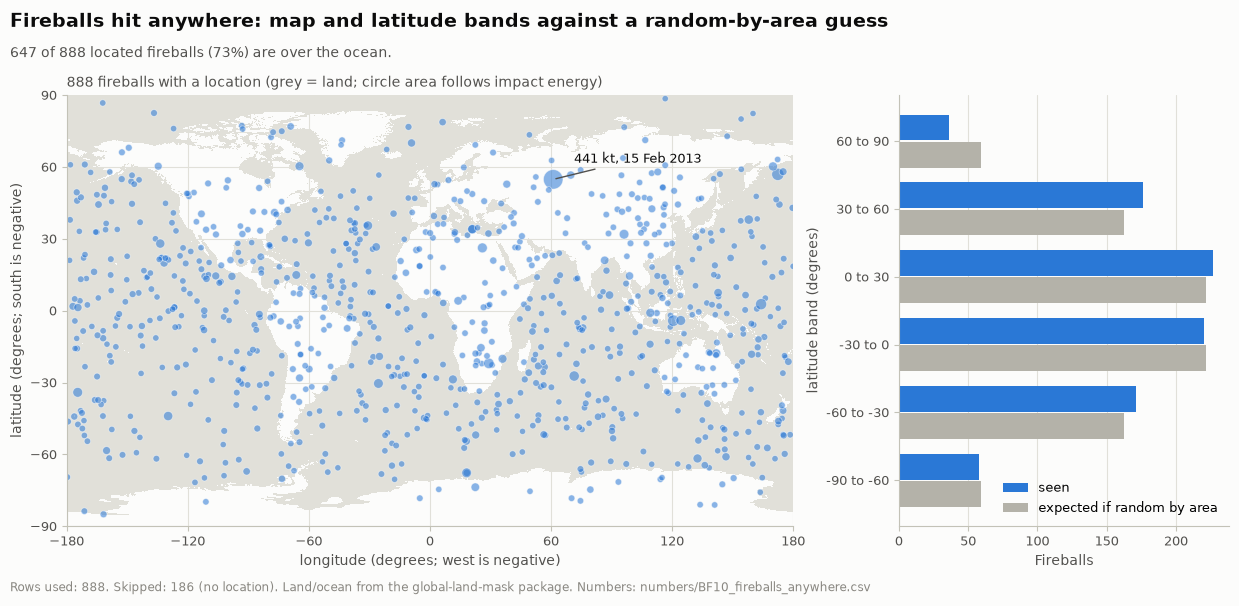

In [4]:
fb = hp.read_csv("fireballs")
fb["t"] = pd.to_datetime(fb["date"], format="%Y-%m-%d %H:%M:%S")
fb["lat_s"] = np.where(fb["lat-dir"] == "S", -fb["lat"], fb["lat"])
fb["lon_s"] = np.where(fb["lon-dir"] == "W", -fb["lon"], fb["lon"])
loc = fb[fb["lat_s"].notna() & fb["lon_s"].notna()].copy()
F = Facts(10, "fireballs_anywhere")
F.add("rows", len(fb)); F.add("located", len(loc))
F.add("first", 0, fb["t"].min().strftime("%Y-%m-%d"), source="our data (date)"); F.add("last", 0, fb["t"].max().strftime("%Y-%m-%d"), source="our data (date)")
edges = [-90, -60, -30, 0, 30, 60, 90]
obs = pd.cut(loc["lat_s"], edges, right=False).value_counts().sort_index()
for (lo, hi), o in zip(zip(edges[:-1], edges[1:]), obs.values):
    share = (np.sin(np.radians(hi)) - np.sin(np.radians(lo))) / 2
    F.add(f"band_{lo}_{hi}_obs", int(o)); F.add(f"band_{lo}_{hi}_exp", share * len(loc), n0(share * len(loc)))
    F.add(f"band_{lo}_{hi}_share", 100 * share, p(100 * share, 1))
F.rule("sin30", np.sin(np.radians(30)), "0.5")
loc["land"] = globe.is_land(loc["lat_s"].to_numpy(), loc["lon_s"].to_numpy())
F.add("over_land", int(loc["land"].sum())); F.add("over_ocean", int((~loc["land"]).sum()))
F.add("ocean_pct", 100 * (~loc["land"]).mean(), p(100 * (~loc["land"]).mean()))
F.outside("earth_ocean_pct", 71, "71%", source="known science (share of Earth's surface covered by ocean)")
top2 = fb.nlargest(2, "impact-e")
big1, big2 = top2.iloc[0], top2.iloc[1]
F.add("big1_kt", big1["impact-e"], n0(big1["impact-e"]), "kt"); F.add("big1_date", 0, big1["t"].strftime("%Y-%m-%d"), source="our data (date)")
F.add("big1_lat", big1["lat"], d(big1["lat"], 1)); F.add("big1_lon", big1["lon"], d(big1["lon"], 1))
F.add("big2_kt", big2["impact-e"], n0(big2["impact-e"]), "kt"); F.add("big2_date", 0, big2["t"].strftime("%Y-%m-%d"), source="our data (date)")
F.add("big_ratio", big1["impact-e"] / big2["impact-e"], n0(big1["impact-e"] / big2["impact-e"]))
F.add("big1_alt", big1["alt"], d(big1["alt"], 1), "km"); F.add("big1_vel", big1["vel"], d(big1["vel"], 1), "km/s")
F.outside("kt_tnt", 1000, "1,000", "tonnes of TNT", source="definition of a kiloton")
F.outside("hiroshima_kt", 15, "15", "kt", source="known science (Hiroshima bomb, about 15 kt)")
F.add("big1_hiroshimas", big1["impact-e"] / 15, n0(big1["impact-e"] / 15))
yrs = fb[(fb["t"].dt.year >= 2005) & (fb["t"].dt.year <= 2025)]
nyrs = 2025 - 2005 + 1
F.rule("years", nyrs, str(nyrs))
for cut, k_ in [(0.1, "01"), (1, "1"), (10, "10")]:
    nn = int((yrs["impact-e"] >= cut).sum())
    F.add(f"n_ge_{k_}", nn); F.add(f"per_year_ge_{k_}", nn / nyrs, d(nn / nyrs, 1))
F.add("every_years_ge_10", nyrs / int((yrs["impact-e"] >= 10).sum()), d(nyrs / int((yrs["impact-e"] >= 10).sum()), 1), "years")
F.rule("band_edge", 30, "30", "degrees"); F.rule("y_from", 2005, "2005"); F.rule("y_to", 2025, "2025")
F.rule("cut_01", 0.1, "0.1", "kt"); F.rule("cut_1", 1, "1", "kt"); F.rule("cut_10", 10, "10", "kt")
F.outside("guide_land", 243, "243", source="Field Guide")
F.add("no_place", len(fb) - len(loc))
print(F.table().to_string()); f10 = F.save()

# map with land shown from the land mask (every 30th cell, about 1/4 degree)
step = 30
mask = globe._mask[::step, ::step]
lat_g, lon_g = globe._lat[::step], globe._lon[::step]
fig, axs = plt.subplots(1, 2, figsize=(15, 5.6), gridspec_kw={"width_ratios": [2.2, 1]})
ax = axs[0]
ax.imshow(np.where(mask, 1.0, np.nan), extent=[lon_g.min(), lon_g.max(), lat_g.min(), lat_g.max()], origin="upper",
          cmap=plt.matplotlib.colors.ListedColormap(["#e1e0d9"]), aspect="auto", interpolation="nearest")
sz = 6 + 60 * np.sqrt(loc["impact-e"].fillna(0) / loc["impact-e"].max())
ax.scatter(loc["lon_s"], loc["lat_s"], s=sz * 3, color=hp.SERIES[0], alpha=0.55, edgecolors=hp.SURFACE, linewidths=0.6)
ax.annotate(f"{big1['impact-e']:.0f} kt, {big1['t']:%d %b %Y}", (loc.loc[big1.name, 'lon_s'], loc.loc[big1.name, 'lat_s']),
            xytext=(15, 12), textcoords="offset points", fontsize=9, color=hp.INK, arrowprops=dict(arrowstyle="-", color=hp.INK_2))
ax.set_xlim(-180, 180); ax.set_ylim(-90, 90); ax.set_xticks(range(-180, 181, 60)); ax.set_yticks(range(-90, 91, 30))
ax.set_xlabel("longitude (degrees; west is negative)"); ax.set_ylabel("latitude (degrees; south is negative)")
ax.set_title(f"{len(loc):,} fireballs with a location (grey = land; circle area follows impact energy)", fontsize=10, color=hp.INK_2)
ax2 = axs[1]
labels = [f"{lo} to {hi}" for lo, hi in zip(edges[:-1], edges[1:])]
expv = [(np.sin(np.radians(hi)) - np.sin(np.radians(lo))) / 2 * len(loc) for lo, hi in zip(edges[:-1], edges[1:])]
yy = np.arange(len(labels))
ax2.barh(yy + 0.2, obs.values, height=0.38, color=hp.SERIES[0], label="seen")
ax2.barh(yy - 0.2, expv, height=0.38, color=hp.GRAY, label="expected if random by area")
ax2.set_yticks(yy, labels); ax2.set_xlabel("Fireballs"); ax2.set_ylabel("latitude band (degrees)")
ax2.legend(loc="lower right"); ax2.grid(axis="y", visible=False)
hp.add_titles(fig, "Fireballs hit anywhere: map and latitude bands against a random-by-area guess",
              f"{int((~loc['land']).sum()):,} of {len(loc):,} located fireballs ({100 * (~loc['land']).mean():.0f}%) are over the ocean.",
              hp.caption(len(loc), len(fb) - len(loc), "no location", "numbers/BF10_fireballs_anywhere.csv",
                         extra="Land/ocean from the global-land-mask package."))
c10 = hp.save_chart(fig, "BF10_fireball_map"); plt.show()
hp.log_entry("C-BF10", "Beginner finding 10 chart: fireball map and latitude bands", step=6, chart=c10, numbers=f10,
             rows_used=len(loc), rows_skipped=f"{len(fb) - len(loc):,} (no location)",
             key_numbers=[f"0 to 30 N: {int(obs.iloc[3])} seen vs {expv[3]:.0f} expected", f"ocean {100 * (~loc['land']).mean():.0f}%",
                          f"biggest {big1['impact-e']:.0f} kt"],
             what_it_shows="Seen counts per latitude band sit close to a random-by-area guess; one fireball is far bigger than the rest.")

## Finding 11: fewer fireballs around dawn

                 key        value  shown   unit           source
0            located   888.000000    888                our data
1             slot_0    91.000000     91                our data
2             slot_2    70.000000     70                our data
3             slot_4    49.000000     49                our data
4             slot_6    52.000000     52                our data
5             slot_8    84.000000     84                our data
6            slot_10    83.000000     83                our data
7            slot_12    86.000000     86                our data
8            slot_14    66.000000     66                our data
9            slot_16    54.000000     54                our data
10           slot_18    72.000000     72                our data
11           slot_20    70.000000     70                our data
12           slot_22   111.000000    111                our data
13     min_slot_from     4.000000      4                our data
14       min_slot_to     

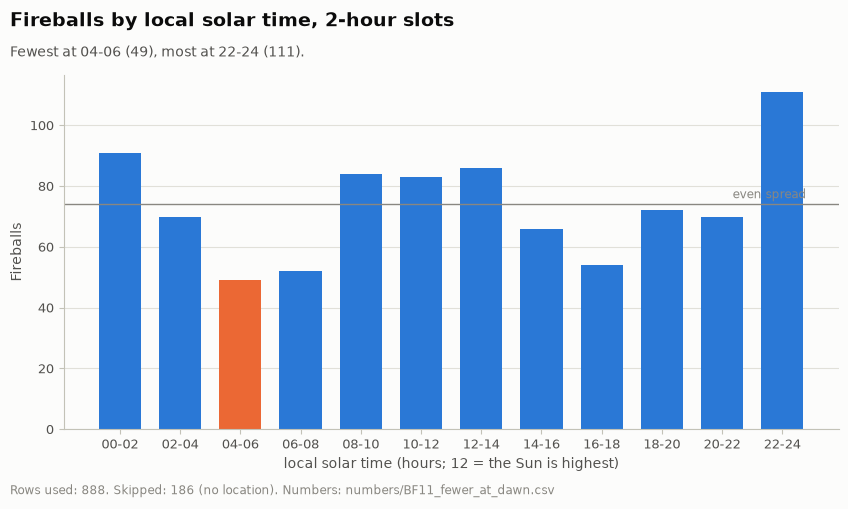

In [5]:
F = Facts(11, "fewer_at_dawn")
loc["lst"] = (loc["t"].dt.hour + loc["t"].dt.minute / 60 + loc["lon_s"] / 15) % 24
slots = pd.cut(loc["lst"], np.arange(0, 25, 2), right=False).value_counts().sort_index()
F.add("located", len(loc))
for (lo, v_) in zip(range(0, 24, 2), slots.values):
    F.add(f"slot_{lo}", int(v_))
lo_i, hi_i = int(np.argmin(slots.values)), int(np.argmax(slots.values))
F.add("min_slot_from", lo_i * 2, str(lo_i * 2)); F.add("min_slot_to", lo_i * 2 + 2, str(lo_i * 2 + 2)); F.add("min_count", int(slots.values[lo_i]))
F.add("max_slot_from", hi_i * 2, str(hi_i * 2)); F.add("max_slot_to", hi_i * 2 + 2, str(hi_i * 2 + 2)); F.add("max_count", int(slots.values[hi_i]))
F.add("avg_slot", len(loc) / 12, n0(len(loc) / 12))
mon = fb["t"].dt.month.value_counts()
F.add("month_min", int(mon.min())); F.add("month_max", int(mon.max())); F.add("rows_all", len(fb))
F.rule("deg_per_hour", 15, "15")
ch = loc.loc[big1.name]
F.add("ex_utc_h", ch["t"].hour, str(ch["t"].hour)); F.add("ex_utc_min", ch["t"].minute, str(ch["t"].minute))
F.add("ex_utc_dec", ch["t"].hour + ch["t"].minute / 60, d(ch["t"].hour + ch["t"].minute / 60, 2))
F.add("ex_lon", ch["lon_s"], d(ch["lon_s"], 1)); F.add("ex_lon_h", ch["lon_s"] / 15, d(ch["lon_s"] / 15, 2))
F.add("ex_local", ch["lst"], d(ch["lst"], 1)); F.add("ex_local_clock", 0, f"{int(ch['lst']):02d}:{int(round((ch['lst'] % 1) * 60)):02d}", source="our data (time)")
half = loc["t"].dt.year < 2010
for nm, sel in [("before2010", half), ("from2010", ~half)]:
    s_ = pd.cut(loc.loc[sel, "lst"], np.arange(0, 25, 2), right=False).value_counts().sort_index()
    F.add(f"{nm}_n", int(sel.sum())); F.add(f"{nm}_dawn", int(s_.values[2])); F.add(f"{nm}_night", int(s_.values[11]))
F.rule("slot_hours", 2, "2", "hours")
F.rule("split_year", 2010, "2010")
print(F.table().to_string()); f11 = F.save()
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.bar(np.arange(12), slots.values, color=[hp.SERIES[1] if k_ == lo_i else hp.SERIES[0] for k_ in range(12)], width=0.7)
ax.axhline(len(loc) / 12, color=hp.INK_MUTED, lw=1)
ax.text(11.4, len(loc) / 12 + 2, "even spread", ha="right", fontsize=8.5, color=hp.INK_MUTED)
ax.set_xticks(np.arange(12), [f"{h:02d}-{h + 2:02d}" for h in range(0, 24, 2)])
ax.set_xlabel("local solar time (hours; 12 = the Sun is highest)"); ax.set_ylabel("Fireballs")
ax.grid(axis="x", visible=False)
hp.add_titles(fig, "Fireballs by local solar time, 2-hour slots",
              f"Fewest at {lo_i * 2:02d}-{lo_i * 2 + 2:02d} ({slots.values[lo_i]}), most at {hi_i * 2:02d}-{hi_i * 2 + 2:02d} ({slots.values[hi_i]}).",
              hp.caption(len(loc), len(fb) - len(loc), "no location", "numbers/BF11_fewer_at_dawn.csv"))
c11 = hp.save_chart(fig, "BF11_local_time"); plt.show()
hp.log_entry("C-BF11", "Beginner finding 11 chart: fireballs by local solar time", step=6, chart=c11, numbers=f11,
             rows_used=len(loc), rows_skipped=f"{len(fb) - len(loc):,} (no location)",
             key_numbers=[f"lowest slot {lo_i * 2:02d}-{lo_i * 2 + 2:02d}: {slots.values[lo_i]}", f"highest {hi_i * 2:02d}-{hi_i * 2 + 2:02d}: {slots.values[hi_i]}"],
             what_it_shows="The dawn slots have the fewest fireballs and the late-evening slot the most.")
hp.edge_case("B", "Full Section B notebook not built (background builder stopped on a usage limit); beginner findings 8-9 were computed in notebooks/BF_B_C_approaches_fireballs.ipynb.")
hp.edge_case("C", "Full Section C notebook not built (background builder stopped on a network error and then a usage limit); beginner findings 10-11 were computed in notebooks/BF_B_C_approaches_fireballs.ipynb.")

## Plain version: "Meet the data" numbers and one plain chart per finding

Numbers for the "Meet the data" text of parts B and C: `numbers/BM_B_meet_close_approaches.csv` and
`numbers/BM_C_meet_fireballs.csv`. New plain charts: `charts/K08_...png` to `charts/K11_...png` (plotted numbers in
`numbers/K08_...csv` ...), drawn with `simple_charts`. The old charts are kept.

In [6]:
kc.plain_style()
M = Meet("B", "meet_close_approaches")
M.add("rows_total", len(ca)); M.add("n_columns", len(hp.columns("close_approaches"))); M.add("objects", ca["des"].nunique())
y0_, y1_ = int(ca["year"].min()), int(ca["year"].max())
M.add("y_first", y0_, str(y0_)); M.add("y_last", y1_, str(y1_)); M.add("n_years", y1_ - y0_ + 1)
M.add("per_year", len(ca) / (y1_ - y0_ + 1), n0(len(ca) / (y1_ - y0_ + 1)), source="our data (rows ÷ years)")
M.rule("range_au", 0.1, "0.1", "AU"); M.add("range_ld", 0.1 / hp.LD_AU, n0(0.1 / hp.LD_AU), "Moon distances")
M.add("range_million_km", 0.1 * hp.AU_KM / 1e6, d(0.1 * hp.AU_KM / 1e6, 0), "million km")
M.add("h_blank", int(ca["h"].isna().sum()))
M.add("passes_per_object", len(ca) / ca["des"].nunique(), d(len(ca) / ca["des"].nunique(), 1))
apo = ca[(ca["des"] == "99942") & (ca["year"] == 2029)].iloc[0]
M.add("apo_name", 0, apo["fullname"].strip(), source="our data (name)"); M.add("apo_des", 0, apo["des"], source="our data (name)")
M.add("apo_cd", 0, apo["cd"], source="our data (date)")
M.add("apo_dist", apo["dist"], g(apo["dist"], 3), "AU"); M.add("apo_km", apo["dist"] * hp.AU_KM, n0(apo["dist"] * hp.AU_KM), "km")
M.add("apo_ld", apo["dist"] / hp.LD_AU, d(apo["dist"] / hp.LD_AU, 2), "Moon distances")
M.add("apo_height", apo["dist"] * hp.AU_KM - hp.EARTH_RADIUS_KM, n0(apo["dist"] * hp.AU_KM - hp.EARTH_RADIUS_KM), "km")
M.add("apo_v", apo["v_rel"], d(apo["v_rel"], 2), "km/s"); M.add("apo_kmh", apo["v_rel"] * 3600, n0(apo["v_rel"] * 3600), "km per hour")
M.add("apo_h", apo["h"], d(apo["h"], 2)); M.add("apo_passes", int((ca["des"] == "99942").sum()))
M.add("apo_year", 2029, "2029", source="our data (year of the example pass)")
M.outside("geo_km", 35786, "35,786", "km", source="known science (height of TV satellites in geostationary orbit)")
M.outside("au_km", hp.AU_KM / 1e6, "149.6", "million km", source="known science (1 AU)")
M.outside("earth_radius", hp.EARTH_RADIUS_KM, "6,371", "km", source="the brief")
M.add("v_median", ca["v_rel"].median(), d(ca["v_rel"].median(), 1), "km/s")
print(M.table().to_string()); fmB = M.save()

M = Meet("C", "meet_fireballs")
M.add("rows_total", len(fb)); M.add("n_columns", len(hp.columns("fireballs")))
M.add("first", 0, fb["t"].min().strftime("%Y-%m-%d"), source="our data (date)"); M.add("last", 0, fb["t"].max().strftime("%Y-%m-%d"), source="our data (date)")
yrs_span = (fb["t"].max() - fb["t"].min()).days / 365.25
M.add("years_span", yrs_span, n0(yrs_span), "years"); M.add("per_year", len(fb) / yrs_span, n0(len(fb) / yrs_span))
M.add("no_place", int(fb["lat"].isna().sum())); M.add("no_alt", int(fb["alt"].isna().sum())); M.add("no_vel", int(fb["vel"].isna().sum()))
ch_ = fb.loc[fb["impact-e"].idxmax()]
M.add("ex_date", 0, ch_["date"], source="our data (date and time)"); M.add("ex_energy", ch_["energy"], n0(ch_["energy"]))
M.add("ex_kt", ch_["impact-e"], n0(ch_["impact-e"]), "kt"); M.add("ex_tonnes", ch_["impact-e"] * 1000, n0(ch_["impact-e"] * 1000), "tonnes of TNT")
M.add("ex_lat", ch_["lat"], d(ch_["lat"], 1)); M.add("ex_latdir", 0, ch_["lat-dir"], source="our data (code)")
M.add("ex_lon", ch_["lon"], d(ch_["lon"], 1)); M.add("ex_londir", 0, ch_["lon-dir"], source="our data (code)")
M.add("ex_alt", ch_["alt"], d(ch_["alt"], 1), "km"); M.add("ex_vel", ch_["vel"], d(ch_["vel"], 1), "km/s")
M.add("ex_kmh", ch_["vel"] * 3600, n0(ch_["vel"] * 3600), "km per hour")
M.outside("plane_km", 11, "11", "km", source="known science (typical cruising height of a passenger plane)")
M.add("ex_alt_vs_plane", ch_["alt"] / 11, d(ch_["alt"] / 11, 1), source="our data ÷ known science")
M.rule("energy_unit", 1e10, "ten billion", "joules")
M.add("kt_median", fb["impact-e"].median(), d(fb["impact-e"].median(), 2), "kt")
print(M.table().to_string()); fmC = M.save()

                  key          value                     shown            unit                                                          source
0          rows_total  120071.000000                   120,071                                                                        our data
1           n_columns      14.000000                        14                                                                        our data
2             objects   28430.000000                    28,430                                                                        our data
3             y_first    1900.000000                      1900                                                                        our data
4              y_last    2199.000000                      2199                                                                        our data
5             n_years     300.000000                       300                                                                        our data

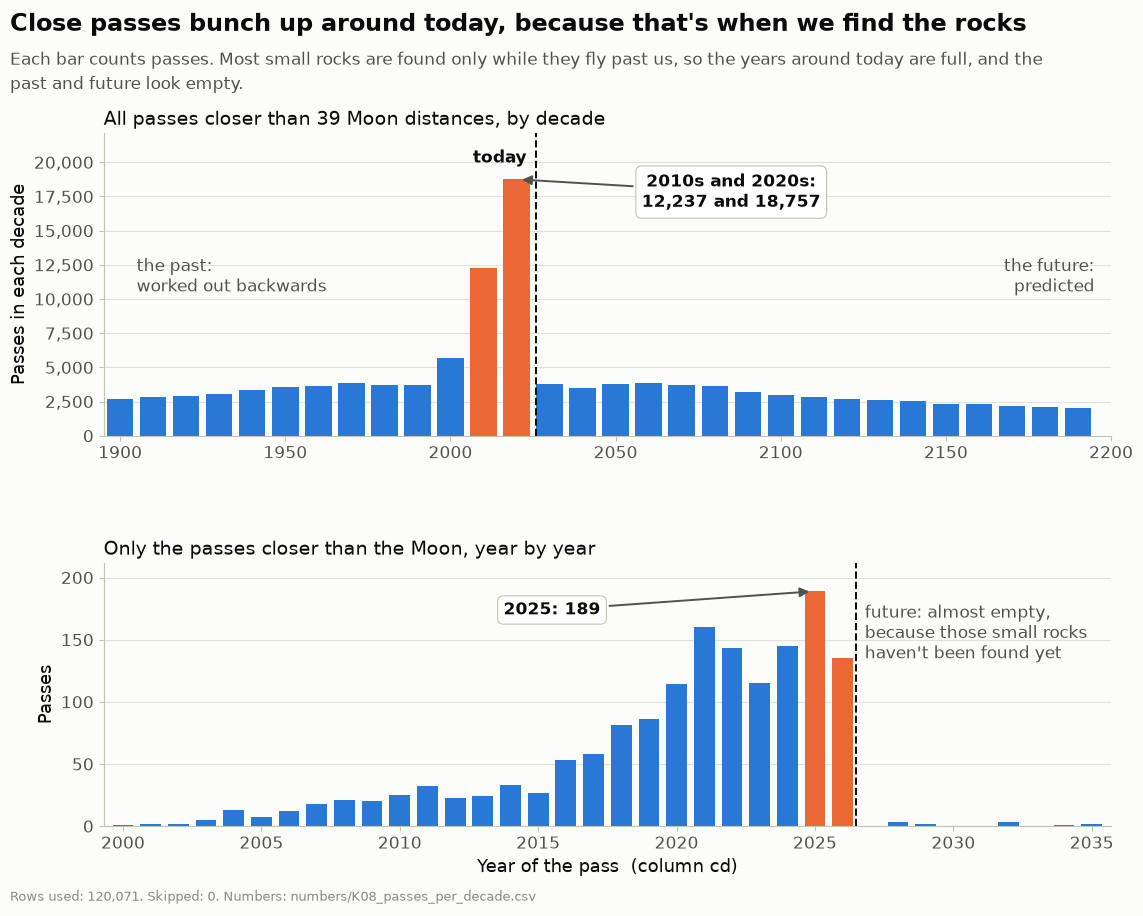

In [7]:
# K08: passes per decade (top) and passes closer than the Moon per year (bottom), with "today" marked
decs = list(range(1900, 2200, 10))
v8 = per_dec.reindex(decs, fill_value=0)
yrs8 = list(range(2000, 2036))
mv8 = mpy.reindex(yrs8, fill_value=0)
t8 = pd.DataFrame({"decade": decs, "passes": v8.values})
n8 = hp.save_numbers(t8, "K08_passes_per_decade"); hp.save_numbers(pd.DataFrame({"year": yrs8, "closer_than_moon": mv8.values}), "K08_passes_per_decade_moon")
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 9), gridspec_kw={"height_ratios": [1.15, 1], "hspace": 0.45})
col8 = [kc.HIGHLIGHT if x in (2010, 2020) else kc.MAIN for x in decs]
ax1.bar(decs, v8.values, width=8, color=col8)
ax1.axvline(2026, color=hp.INK, lw=1.4, ls="--")
kc.label(ax1, 2023, v8.max() * 1.05, "today", ha="right", va="bottom", bold=True)
kc.label(ax1, 1905, v8.max() * 0.62, "the past:\nworked out backwards", ha="left", va="center", color=hp.INK_2)
kc.label(ax1, 2195, v8.max() * 0.62, "the future:\npredicted", ha="right", va="center", color=hp.INK_2)
kc.point_at(ax1, (2020, v8[2020]), f"2010s and 2020s:\n{n0(v8[2010])} and {n0(v8[2020])}", (2085, v8.max() * 0.95))
ax1.set_xticks(range(1900, 2201, 50)); ax1.set_xlim(1895, 2200); ax1.set_ylim(0, v8.max() * 1.18)
ax1.set_ylabel("Passes in each decade"); kc.plain_axis(ax1, "y"); ax1.grid(axis="x", visible=False)
ax1.set_title(f"All passes closer than {n0(0.1 / hp.LD_AU)} Moon distances, by decade", fontsize=13.5, color=hp.INK, loc="left")
ax2.bar(yrs8, mv8.values, width=0.75, color=[kc.HIGHLIGHT if y_ in (2025, 2026) else kc.MAIN for y_ in yrs8])
ax2.axvline(2026.5, color=hp.INK, lw=1.4, ls="--")
kc.label(ax2, 2026.8, mv8.max() * 0.95, "future: almost empty,\nbecause those small rocks\nhaven't been found yet", ha="left", va="top", color=hp.INK_2)
kc.point_at(ax2, (2025, mv8[2025]), f"2025: {mv8[2025]}", (2015.5, mv8.max() * 0.92))
ax2.set_xlim(1999.3, 2035.7); ax2.set_ylim(0, mv8.max() * 1.12)
ax2.set_ylabel("Passes"); kc.plain_axis(ax2, "y"); ax2.grid(axis="x", visible=False)
ax2.set_xlabel("Year of the pass  (column cd)")
ax2.set_title("Only the passes closer than the Moon, year by year", fontsize=13.5, color=hp.INK, loc="left")
kc.titles(fig, "Close passes bunch up around today, because that's when we find the rocks",
          "Each bar counts passes. Most small rocks are found only while they fly past us, so the years around today are "
          "full, and the past and future look empty.",
          hp.caption(len(ca), 0, "", n8))
c8_ = kc.save(fig, "K08_passes_per_decade"); plt.show()
hp.log_entry("B-K08", "Simple chart for finding 8: passes per decade and closer-than-Moon passes per year", step=6, chart=c8_,
             numbers=n8, rows_used=len(ca), key_numbers=[f"2010s {per_dec[2010]:,}; 2020s {per_dec[2020]:,}; 2030s {per_dec[2030]:,}"],
             what_it_shows="Passes pile up in the 2010s and 2020s; closer-than-Moon passes drop to almost none after 2026.")

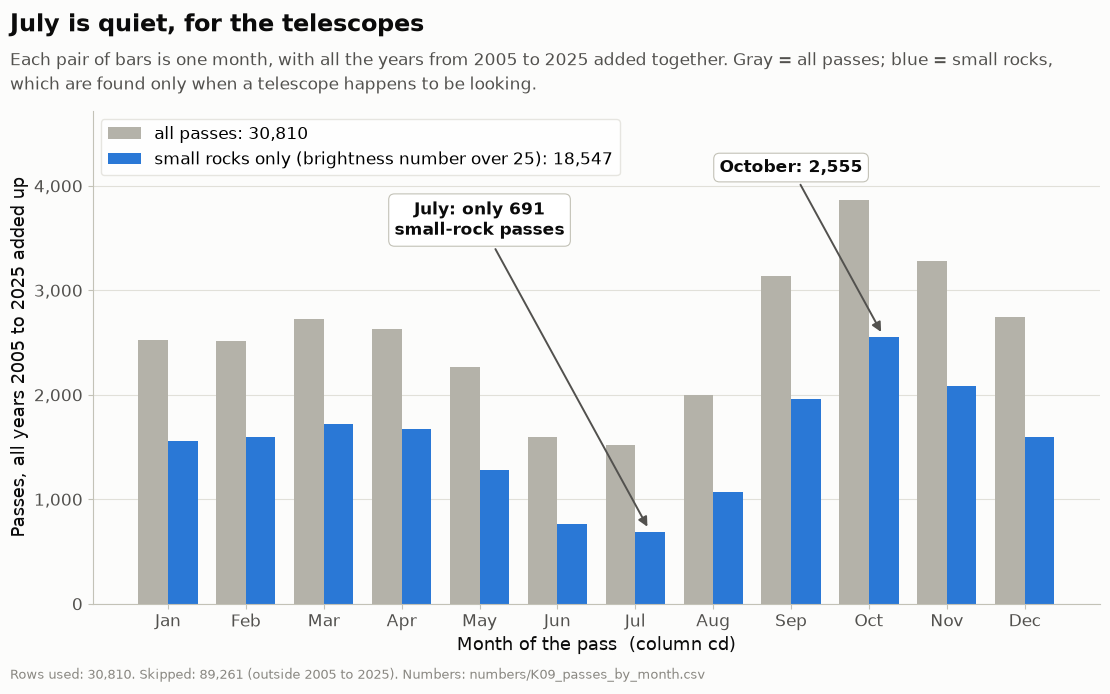

In [8]:
# K09: passes by calendar month, 2005 to 2025: all passes (gray) and small rocks (blue)
MON = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
t9 = pd.DataFrame({"month": MON, "all_passes": ma_.values, "small_rocks_h_over_25": ms.values})
n9 = hp.save_numbers(t9, "K09_passes_by_month")
fig, ax = plt.subplots(figsize=(13, 6.4))
x9 = np.arange(12); w9 = 0.38
ax.bar(x9 - w9 / 2, ma_.values, width=w9, color=kc.OTHER, label=f"all passes: {n0(len(w))}")
ax.bar(x9 + w9 / 2, ms.values, width=w9, color=kc.MAIN, label=f"small rocks only (brightness number over 25): {n0(len(small))}")
kc.point_at(ax, (6 + w9 / 2, ms[7]), f"July: only {n0(ms[7])}\nsmall-rock passes", (4.0, ma_.max() * 0.95))
kc.point_at(ax, (9 + w9 / 2, ms[10]), f"October: {n0(ms[10])}", (8.0, ma_.max() * 1.08))
ax.set_xticks(x9, MON); ax.set_ylim(0, ma_.max() * 1.22)
ax.set_xlabel("Month of the pass  (column cd)"); ax.set_ylabel("Passes, all years 2005 to 2025 added up")
kc.plain_axis(ax, "y"); ax.grid(axis="x", visible=False)
ax.legend(loc="upper left", frameon=True, facecolor="white", edgecolor=hp.GRID)
kc.titles(fig, "July is quiet, for the telescopes",
          "Each pair of bars is one month, with all the years from 2005 to 2025 added together. Gray = all passes; "
          "blue = small rocks, which are found only when a telescope happens to be looking.",
          hp.caption(len(w), len(ca) - len(w), "outside 2005 to 2025", n9))
c9_ = kc.save(fig, "K09_passes_by_month"); plt.show()
hp.log_entry("B-K09", "Simple chart for finding 9: passes by month", step=6, chart=c9_, numbers=n9, rows_used=len(w),
             key_numbers=[f"small rocks: July {ms[7]:,}, October {ms[10]:,}"],
             what_it_shows="Small-rock passes dip in July and peak in the autumn.")

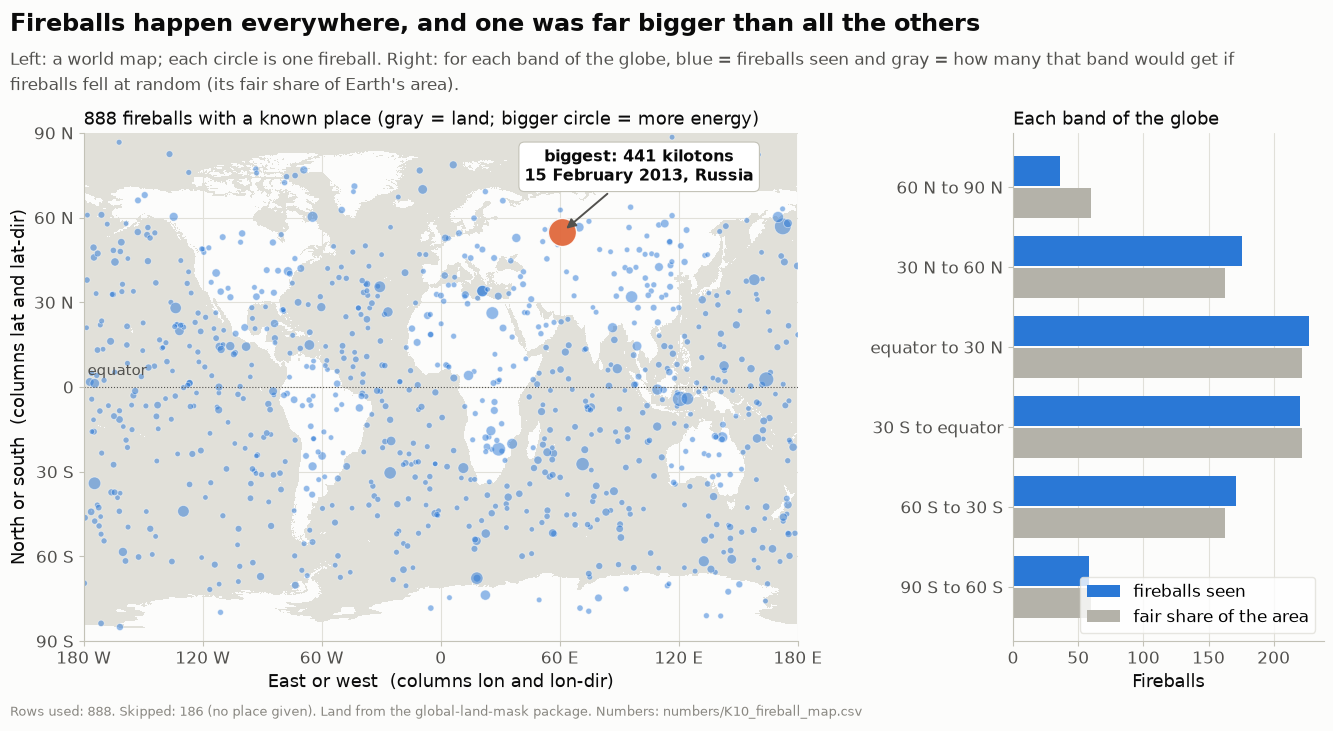

In [9]:
# K10: where fireballs happened (map) and each band of the globe against its fair share of the area
t10 = pd.DataFrame({"band": [f"{lo} to {hi}" for lo, hi in zip(edges[:-1], edges[1:])], "seen": obs.values,
                    "expected_if_random": [round((np.sin(np.radians(hi)) - np.sin(np.radians(lo))) / 2 * len(loc), 1)
                                           for lo, hi in zip(edges[:-1], edges[1:])]})
n10 = hp.save_numbers(t10, "K10_fireball_map")
fig, (axm, axb) = plt.subplots(1, 2, figsize=(16, 6.6), gridspec_kw={"width_ratios": [2.3, 1], "wspace": 0.42})
axm.imshow(np.where(mask, 1.0, np.nan), extent=[lon_g.min(), lon_g.max(), lat_g.min(), lat_g.max()], origin="upper",
           cmap=plt.matplotlib.colors.ListedColormap(["#e1e0d9"]), aspect="auto", interpolation="nearest")
sz10 = 10 + 400 * np.sqrt(loc["impact-e"].fillna(0) / loc["impact-e"].max())
axm.scatter(loc["lon_s"], loc["lat_s"], s=sz10, color=kc.MAIN, alpha=0.5, edgecolors="white", linewidths=0.6)
bx, by = loc.loc[big1.name, "lon_s"], loc.loc[big1.name, "lat_s"]
axm.scatter([bx], [by], s=sz10[big1.name], color=kc.HIGHLIGHT, alpha=0.9, edgecolors="white", linewidths=1)
kc.point_at(axm, (bx, by), f"biggest: {n0(big1['impact-e'])} kilotons\n{big1['t']:%d %B %Y}, Russia", (100, 78), fontsize=11.5)
axm.axhline(0, color=hp.INK_2, lw=0.8, ls=":")
kc.label(axm, -178, 3, "equator", ha="left", va="bottom", fontsize=10.5, color=hp.INK_2)
axm.set_xlim(-180, 180); axm.set_ylim(-90, 90); axm.set_xticks(range(-180, 181, 60)); axm.set_yticks(range(-90, 91, 30))
axm.set_xticklabels(["180 W", "120 W", "60 W", "0", "60 E", "120 E", "180 E"])
axm.set_yticklabels(["90 S", "60 S", "30 S", "0", "30 N", "60 N", "90 N"])
axm.set_xlabel("East or west  (columns lon and lon-dir)"); axm.set_ylabel("North or south  (columns lat and lat-dir)")
axm.set_title(f"{n0(len(loc))} fireballs with a known place (gray = land; bigger circle = more energy)", fontsize=13, color=hp.INK, loc="left")
yy10 = np.arange(len(t10))
axb.barh(yy10 + 0.2, t10["seen"], height=0.38, color=kc.MAIN, label="fireballs seen")
axb.barh(yy10 - 0.2, t10["expected_if_random"], height=0.38, color=kc.OTHER, label="fair share of the area")
axb.set_yticks(yy10, ["90 S to 60 S", "60 S to 30 S", "30 S to equator", "equator to 30 N", "30 N to 60 N", "60 N to 90 N"])
axb.set_xlabel("Fireballs"); axb.grid(axis="y", visible=False)
axb.legend(loc="lower right", frameon=True, facecolor="white", edgecolor=hp.GRID)
axb.set_title("Each band of the globe", fontsize=13, color=hp.INK, loc="left")
kc.titles(fig, "Fireballs happen everywhere, and one was far bigger than all the others",
          "Left: a world map; each circle is one fireball. Right: for each band of the globe, blue = fireballs seen and "
          "gray = how many that band would get if fireballs fell at random (its fair share of Earth's area).",
          hp.caption(len(loc), len(fb) - len(loc), "no place given", n10, extra="Land from the global-land-mask package."))
c10_ = kc.save(fig, "K10_fireball_map"); plt.show()
hp.log_entry("C-K10", "Simple chart for finding 10: fireball map and fair-share bands", step=6, chart=c10_, numbers=n10,
             rows_used=len(loc), key_numbers=[f"equator to 30 N: seen {int(obs.iloc[3])}, fair share {t10['expected_if_random'].iloc[3]:.0f}"],
             what_it_shows="Each band gets about its fair share of the area; the biggest fireball stands out.")

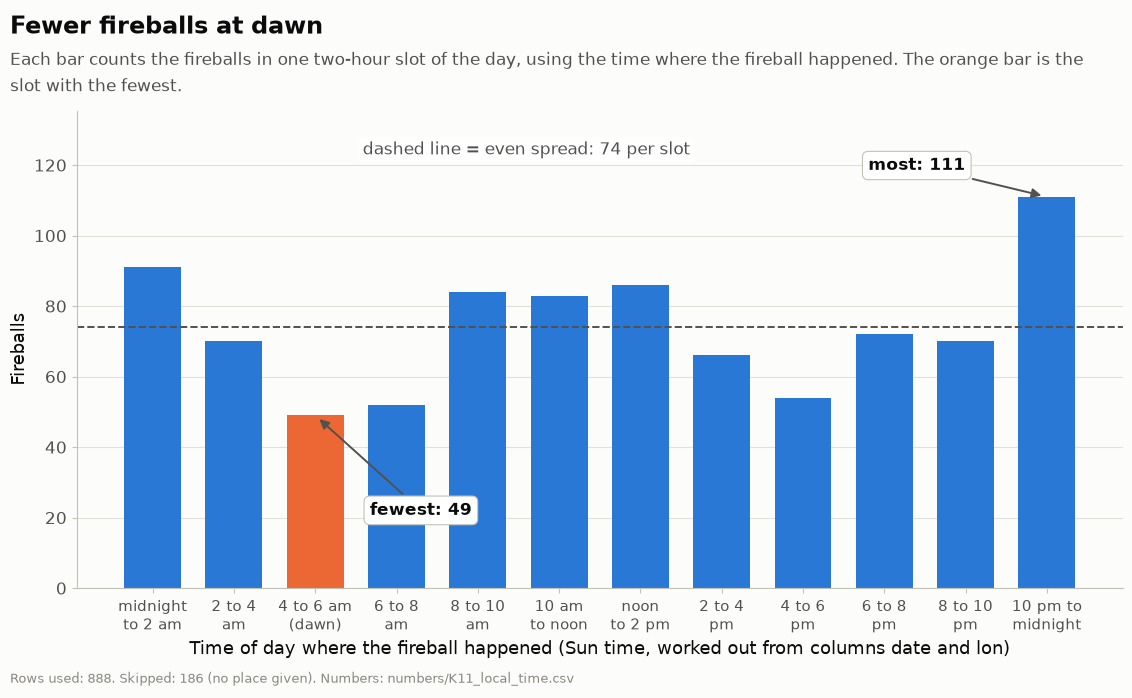

In [10]:
# K11: fireballs by local Sun time, in 2-hour slots
lab11 = ["midnight\nto 2 am", "2 to 4\nam", "4 to 6 am\n(dawn)", "6 to 8\nam", "8 to 10\nam", "10 am\nto noon", "noon\nto 2 pm",
         "2 to 4\npm", "4 to 6\npm", "6 to 8\npm", "8 to 10\npm", "10 pm to\nmidnight"]
t11 = pd.DataFrame({"slot": [l_.replace("\n", " ") for l_ in lab11], "fireballs": slots.values})
n11 = hp.save_numbers(t11, "K11_local_time")
fig, ax = plt.subplots(figsize=(13.5, 6.2))
ax.bar(np.arange(12), slots.values, color=[kc.HIGHLIGHT if k_ == lo_i else kc.MAIN for k_ in range(12)], width=0.7)
ax.axhline(len(loc) / 12, color=hp.INK_2, lw=1.4, ls="--")
kc.label(ax, 4.6, slots.values.max() * 1.12, f"dashed line = even spread: {n0(len(loc) / 12)} per slot", ha="center",
         va="center", color=hp.INK_2, box=True)
kc.point_at(ax, (lo_i, slots.values[lo_i]), f"fewest: {slots.values[lo_i]}", (lo_i + 1.3, slots.values[lo_i] * 0.45))
kc.point_at(ax, (hi_i, slots.values[hi_i]), f"most: {slots.values[hi_i]}", (hi_i - 1.6, slots.values[hi_i] * 1.08))
ax.set_xticks(np.arange(12), lab11, fontsize=11); ax.set_ylim(0, slots.values.max() * 1.22)
ax.set_xlabel("Time of day where the fireball happened (Sun time, worked out from columns date and lon)")
ax.set_ylabel("Fireballs"); kc.plain_axis(ax, "y"); ax.grid(axis="x", visible=False)
kc.titles(fig, "Fewer fireballs at dawn",
          "Each bar counts the fireballs in one two-hour slot of the day, using the time where the fireball happened. "
          "The orange bar is the slot with the fewest.",
          hp.caption(len(loc), len(fb) - len(loc), "no place given", n11))
c11_ = kc.save(fig, "K11_local_time"); plt.show()
hp.log_entry("C-K11", "Simple chart for finding 11: fireballs by local Sun time", step=6, chart=c11_, numbers=n11,
             rows_used=len(loc), key_numbers=[f"fewest {slots.values[lo_i]} (4 to 6 am), most {slots.values[hi_i]}"],
             what_it_shows="The dawn slot has the fewest fireballs; the late evening the most.")